In [37]:
!pip install qiskit requests qiskit-aer scikit-learn pandas numpy matplotlib ucimlrepo -q

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import requests
import io
import zipfile

In [39]:
#Fetch SIRT16 Dataset from UCI repository
try:
  url = "https://archive.ics.uci.edu/static/public/748/sirtuin6+small+molecules-1.zip"
  response = requests.get(url)
  response.raise_for_status()

  with zipfile.ZipFile(io.BytesIO(response.content)) as z:

        file_list = z.namelist()
        print("File Found:", file_list)


        data_file = next((f for f in file_list if f.endswith('.csv') or '.data' in f or 'sirt' in f.lower()), file_list[0])

        with z.open(data_file) as f:

            try:
                df = pd.read_csv(f)
            except:
                f.seek(0)
                df = pd.read_csv(f, sep=None, engine='python')

  print(f"dataset loaded successfully! Shape: {df.shape}")
except Exception as e:
  print(f"Error loading via ucimlrepo: {e}")


File Found: ['SIRTUIN6.csv']
dataset loaded successfully! Shape: (100, 7)


In [40]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)
print(df.head)

<bound method NDFrame.head of         SC-5     SP-6      SHBd  minHaaCH   maxwHBa       FMF     Class
0   0.540936  7.64192  0.162171  0.445270  2.205570  0.467742  High_BFE
1   0.815332  6.59011  0.000000  0.497445  2.003140  0.415385  High_BFE
2   0.734399  6.85522  0.000000  0.507748  1.885900  0.400000  High_BFE
3   0.624557  7.00949  0.450300  0.483648  2.027570  0.500000  High_BFE
4   0.460290  4.92643  0.448998  0.482293  2.064380  0.536585  High_BFE
5   0.739251  5.30234  0.000000  0.503995  1.840170  0.428571  High_BFE
6   0.282118  4.41568  0.417064  0.392469  2.196950  0.323077  High_BFE
7   0.359117  5.16718  0.000000  0.366074  2.268620  0.387097  High_BFE
8   0.535463  5.42374  0.556780  0.489314  1.927500  0.418182  High_BFE
9   0.553846  6.64192  0.430540  0.480831  1.987580  0.482143  High_BFE
10  0.770928  5.90091  0.323544  0.494985  1.945050  0.403846  High_BFE
11  0.381723  5.19560  0.479925  0.462768  2.179640  0.440000  High_BFE
12  0.274972  4.34101  1.238610  0

In [41]:
# Clean dataset: Drop missing values if any
df = df.dropna()
X_clean = df.iloc[:, :-1]
y_clean = df.iloc[:, -1]
print(X_clean.shape)
print(y_clean.shape)
print(f"Data_number: {X_clean.shape[0]}, Feature_number: {X_clean.shape[1]}")
print(X_clean.head)

(100, 6)
(100,)
Data_number: 100, Feature_number: 6
<bound method NDFrame.head of         SC-5     SP-6      SHBd  minHaaCH   maxwHBa       FMF
0   0.540936  7.64192  0.162171  0.445270  2.205570  0.467742
1   0.815332  6.59011  0.000000  0.497445  2.003140  0.415385
2   0.734399  6.85522  0.000000  0.507748  1.885900  0.400000
3   0.624557  7.00949  0.450300  0.483648  2.027570  0.500000
4   0.460290  4.92643  0.448998  0.482293  2.064380  0.536585
5   0.739251  5.30234  0.000000  0.503995  1.840170  0.428571
6   0.282118  4.41568  0.417064  0.392469  2.196950  0.323077
7   0.359117  5.16718  0.000000  0.366074  2.268620  0.387097
8   0.535463  5.42374  0.556780  0.489314  1.927500  0.418182
9   0.553846  6.64192  0.430540  0.480831  1.987580  0.482143
10  0.770928  5.90091  0.323544  0.494985  1.945050  0.403846
11  0.381723  5.19560  0.479925  0.462768  2.179640  0.440000
12  0.274972  4.34101  1.238610  0.503565  2.024220  0.536585
13  0.816281  6.78098  0.360264  0.506231  1.89416

In [25]:
#convert target to 0 & 1
y_values = y_clean.values.ravel() if hasattr(y_clean, 'values') else np.array(y_clean)
unique_labels = np.unique(y_values)
y_binary = np.where(y_values == unique_labels[0], 0, 1)
print(f"Data_number: {X_clean.shape[0]}, Feature_number: {X_clean.shape[1]}")

Data_number: 100, Feature_number: 6


In [42]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import recall_score as recall
from sklearn.metrics import precision_score as precision
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc

# 1. Split dataset (Train / Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_binary, test_size=0.25, random_state=42, stratify=y_binary
)

# 2. Standardize features (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training_sample: {X_train_scaled.shape[0]}, Test_sample: {X_test_scaled.shape[0]}")

# 3. Train Logistic Regression Baseline
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# 4. Train SVM Baseline
svm_model = SVC(kernel='rbf', random_state=42, probability=True)
svm_model.fit(X_train_scaled, y_train)
svm_preds = svm_model.predict(X_test_scaled)
#5. Random Forest
rf_model = RandomForestClassifier(n_estimators = 100 , random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)
#6. KNN
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled, y_train)
knn_preds = knn_model.predict(X_test_scaled)
#7. Simple MLP
mlp_model = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, random_state=42)
mlp_model.fit(X_train_scaled, y_train)
mlp_preds = mlp_model.predict(X_test_scaled)
# 5. Print Results
print("\n--- (Classical Baselines) ---")
classification_report = {
    "Model": ["Logistic Regression", "SVM", "Random Forest", "KNN", "MLP"],
    "Accuracy": [accuracy_score(y_test, lr_preds),
                 accuracy_score(y_test, svm_preds),
                 accuracy_score(y_test, rf_preds),
                 accuracy_score(y_test, knn_preds),
                 accuracy_score(y_test, mlp_preds)],
    "Macro F1-Score": [f1_score(y_test, lr_preds, average='macro'),
                       f1_score(y_test, svm_preds, average='macro'),
                       f1_score(y_test, rf_preds, average='macro'),
                       f1_score(y_test, knn_preds, average='macro'),
                       f1_score(y_test, mlp_preds, average='macro')],
    "Recall":[recall(y_test,lr_preds),
              recall(y_test,svm_preds),
              recall(y_test,rf_preds),
              recall(y_test,knn_preds),
              recall(y_test,mlp_preds)],
    "Precision":[precision(y_test,lr_preds),
                 precision(y_test,svm_preds),
                 precision(y_test,rf_preds),
                 precision(y_test,knn_preds),
                 precision(y_test,mlp_preds)],
    "Confusion Matrix":[confusion_matrix(y_test, lr_preds),
                        confusion_matrix(y_test, svm_preds),
                        confusion_matrix(y_test, rf_preds),
                        confusion_matrix(y_test, knn_preds),
                        confusion_matrix(y_test, mlp_preds)]
}
classification_report_df = pd.DataFrame(classification_report)
print("\n--- Classical Models Comparison ---")
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)
print(classification_report_df)
#

Training_sample: 75, Test_sample: 25

--- (Classical Baselines) ---

--- Classical Models Comparison ---
                 Model  Accuracy  Macro F1-Score    Recall  Precision    Confusion Matrix
0  Logistic Regression      0.80        0.798712  0.916667   0.733333   [[9, 4], [1, 11]]
1                  SVM      0.84        0.837662  1.000000   0.750000   [[9, 4], [0, 12]]
2        Random Forest      0.80        0.800000  0.833333   0.769231  [[10, 3], [2, 10]]
3                  KNN      0.64        0.630542  0.500000   0.666667   [[10, 3], [6, 6]]
4                  MLP      0.76        0.759615  0.750000   0.750000   [[10, 3], [3, 9]]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


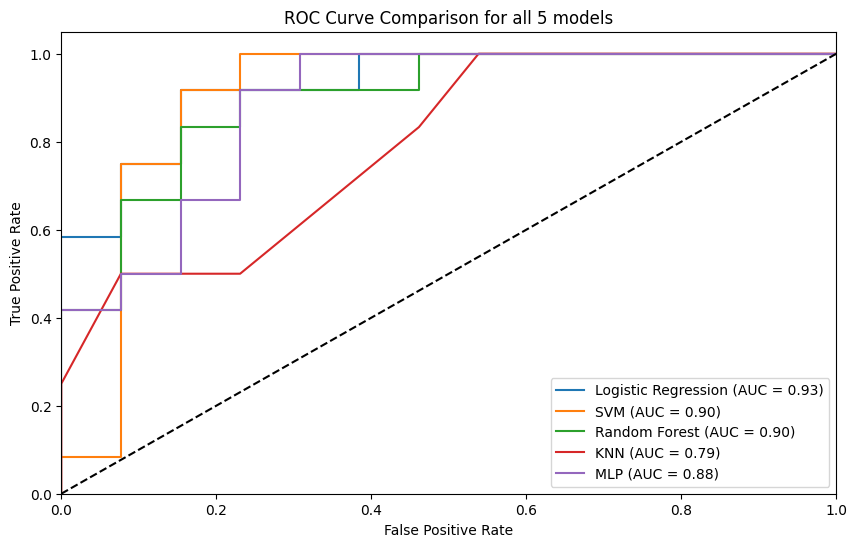

In [43]:
#ROC_curves and AUC
plt.figure(figsize=(10, 6))
for name , model in zip(["Logistic Regression", "SVM", "Random Forest", "KNN", "MLP"], [lr_model, svm_model, rf_model, knn_model, mlp_model]):
  y_prob = model.predict_proba(X_test_scaled)[:, 1]
  fpr, tpr, _ = roc_curve(y_test, y_prob)
  roc_auc = auc(fpr, tpr)
  plt.plot(fpr,tpr,label=f"{name} (AUC = {roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison for all 5 models')
plt.legend(loc='lower right')
plt.show()

In [44]:
#Feature Reduction
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X_clean.columns.to_list()
print("--- Feature Importance Ranking ---")
ranked_features = []
for f in range(X_train.shape[1]):
  idx = indices[f]
  ranked_features.append(feature_names[idx])
  print(f"{f+1}. {feature_names[idx]} ({importances[idx]:.4f})")

--- Feature Importance Ranking ---
1. SP-6 (0.3336)
2. FMF (0.2415)
3. minHaaCH (0.1362)
4. SC-5 (0.1360)
5. maxwHBa (0.0910)
6. SHBd (0.0616)


In [45]:
top_6_features = ranked_features[:6]
top_4_features = ranked_features[:4]
top_2_features = ranked_features[:2]
print(f"Top 6 Features: {top_6_features}")
print(f"Top 4 Features: {top_4_features}")
print(f"Top 2 Features: {top_2_features}")

Top 6 Features: ['SP-6', 'FMF', 'minHaaCH', 'SC-5', 'maxwHBa', 'SHBd']
Top 4 Features: ['SP-6', 'FMF', 'minHaaCH', 'SC-5']
Top 2 Features: ['SP-6', 'FMF']


In [46]:
X_train_subsets = {
    "6_features": X_train_scaled[:, [feature_names.index(f) for f in top_6_features]],
    "4_features": X_train_scaled[:, [feature_names.index(f) for f in top_4_features]],
    "2_features": X_train_scaled[:, [feature_names.index(f) for f in top_2_features]]
}
X_test_subsets = {
    "6_features": X_test_scaled[:, [feature_names.index(f) for f in top_6_features]],
    "4_features": X_test_scaled[:, [feature_names.index(f) for f in top_4_features]],
    "2_features": X_test_scaled[:, [feature_names.index(f) for f in top_2_features]]
}

Our Custom VQC

In [47]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
def run_custom_vqc_statevector(X_train_sub,X_test_sub,y_train,y_test, n_layers=2,maxiter = 150):
  n_qubits = X_train_sub.shape[1]
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train_sub)
  X_test_scaled = scaler.transform(X_test_sub)

  X_train_angles = 2*np.arctan(X_train_scaled)
  X_test_angles = 2*np.arctan(X_test_scaled)

  #building the Quantum circuit
  x_params = ParameterVector('x', n_qubits)
  theta = ParameterVector('theta', n_layers*n_qubits)
  qc = QuantumCircuit(n_qubits)
  #Feature map
  for i in range(n_qubits):
    qc.ry(x_params[i], i)

  #trainiable variational layers
  for layer in range(n_layers):
    for qubit in range(n_qubits):
      qc.ry(theta[layer*n_qubits + qubit], qubit)
    for qubit in range(n_qubits-1):
      qc.cx(qubit, qubit+1)

  #Statevector calculations
  basis_indices = np.array(2**n_qubits)
  class_one_mask = ((basis_indices>>(n_qubits-1))&1).astype(bool)

  def predict_probability_one(features, weights):
    bindings = {x_params[i]: float(features[i]) for i in range(n_qubits)}
    bindings.update({theta[i]: float(weights[i])for i in range (len(weights))})
    bound_qc = qc.assign_parameters(bindings)
    state = Statevector.from_instruction(bound_qc)
    probabilities = state.probabilities()
    return float(probabilities[class_one_mask].sum())

  loss_history = []

  def loss_function(weights, X, y):
    probs = np.array([predict_probability_one(row, weights) for row in X])
    probs = np.clip(probs, 1e-7 , 1 - 1e-7)
    current_loss = -np.mean(y*np.log(probs)+(1-y)*np.log(1-probs))
    loss_history.append(current_loss)
    return current_loss



  rng = np.random.default_rng(seed=42)
  initial_weights = rng.uniform(-0.1,0.1, size = n_qubits*n_layers)

  result = minimize(loss_function,
                    initial_weights,
                    args=(X_train_angles, y_train),
                    method='COBYLA',
                    options={'maxiter': maxiter})
  trained_weights = result.x
  vqc_probs = np.array([predict_probability_one(row, trained_weights) for row in X_test_angles])
  vqc_preds = (vqc_probs >= 0.5).astype(int)
  acc = accuracy_score(y_test, vqc_preds)
  f1 = f1_score(y_test, vqc_preds, average = "macro")
  #learing curve ploting
  plt.figure(figsize=(10, 6))
  plt.plot(
      range(1, len(loss_history)+1) ,
      loss_history,
      marker = "o",
      linestyle = "-",
      color = "#1f77b4",
      linewidth = 2,
      label='Custom VQC Training Loss'
      )
  plt.xlabel('Optimization Iteration', fontsize = 12)
  plt.ylabel('Cost/Loss Value', fontsize = 12)
  plt.grid(True, linestyle = '--', alpha = 0.6)
  plt.title("VQC Learning Curve (SIRT16 Dataset)", fontsize=14)
  plt.legend(fontsize = 12)
  plt.tight_layout()
  plt.savefig('vqc_learning_curve.png', dpi=300)
  plt.show()
  return acc , f1 , trained_weights



--- Running StateVector for 6_features ---


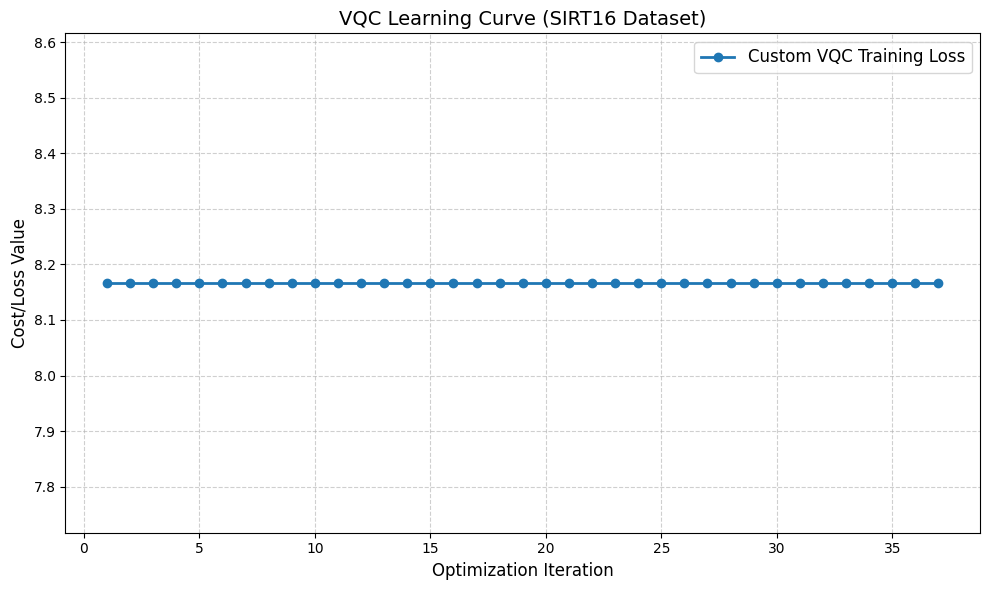

6_features Results --> Accuracy: 0.5200| Macro F1: 0.3421

--- Running StateVector for 4_features ---


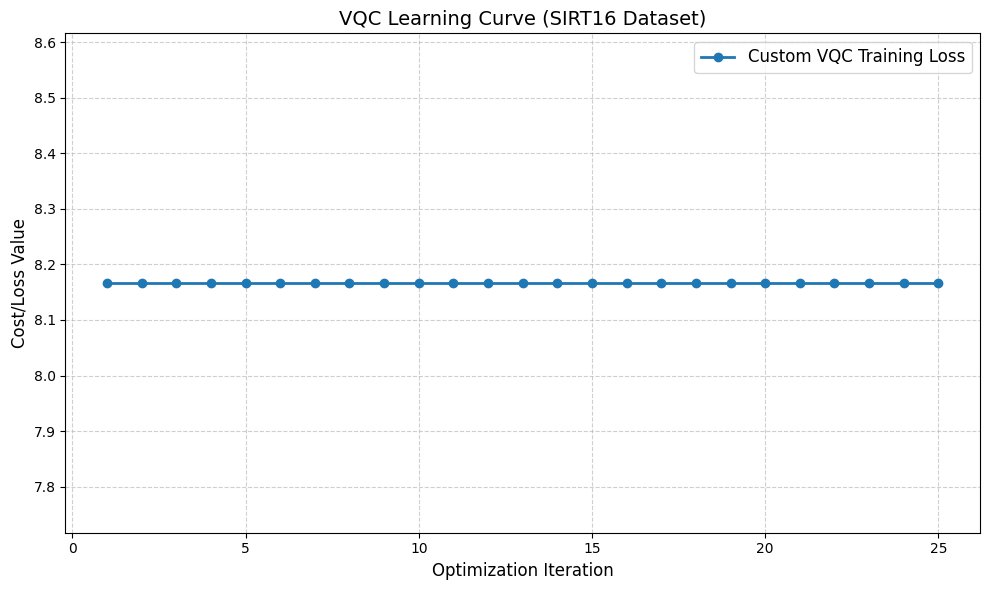

4_features Results --> Accuracy: 0.5200| Macro F1: 0.3421

--- Running StateVector for 2_features ---


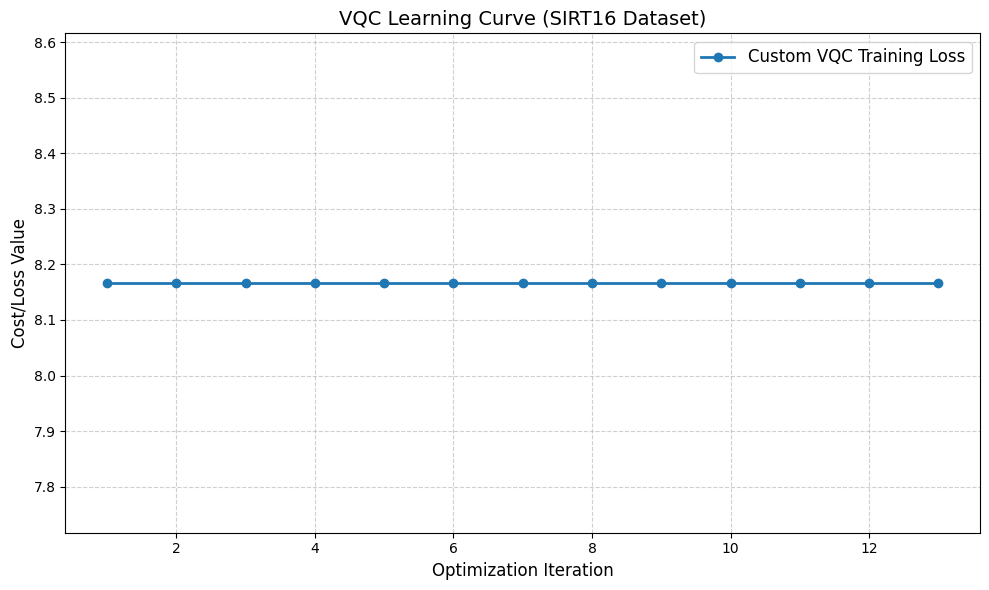

2_features Results --> Accuracy: 0.5200| Macro F1: 0.3421


In [48]:
results_statevector = {}
for tier_name, X_train in X_train_subsets.items():
  X_test = X_test_subsets[tier_name]
  print(f"\n--- Running StateVector for {tier_name} ---")
  acc, f1, trained_weights = run_custom_vqc_statevector(X_train, X_test, y_train, y_test)
  results_statevector[tier_name] = {"Accuracy": acc, "Macro F1": f1}
  print(f"{tier_name} Results --> Accuracy: {acc:.4f}| Macro F1: {f1:.4f}")
#

In [49]:
!pip install qiskit-ibm-runtime -q

In [53]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score

#  "apikey":


service = QiskitRuntimeService(channel="ibm_quantum_platform",token="ibm_token")
backend = service.least_busy(operational=True, simulator=False)
print(f"Using backend: {backend.name}")


pm = generate_preset_pass_manager(backend=backend, optimization_level=1)


num_features = 6
n_layers = 2
x_params = ParameterVector("x", num_features)
theta = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_params[i], i)

for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(theta[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)

qc.measure_all()


sampler = Sampler(mode=backend)
shots = 1024


def get_probability_one(features, weights):
    bindings = {x_params[i]: float(features[i]) for i in range(num_features)}
    bindings.update({theta[i]: float(weights[i]) for i in range(len(weights))})
    bound_qc = qc.assign_parameters(bindings)

    isa_qc = pm.run(bound_qc)

    job = sampler.run([isa_qc], shots=shots)
    result = job.result()
    counts = result[0].data.meas.get_counts()

    prob_one = 0.0
    total_shots = sum(counts.values())
    for bitstring, count in counts.items():
        if bitstring[0] == '1':
            prob_one += count / total_shots
    return prob_one


def loss_function(weights, X, y):
    probs = np.array([get_probability_one(row, weights) for row in X])
    probs = np.clip(probs, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(probs) + (1 - y) * np.log(1 - probs))

rng = np.random.default_rng(42)
initial_weights = rng.uniform(-0.1, 0.1, size=len(theta))

print("Training on IBM Quantum hardware (this may take a while)...")

result = minimize(
    loss_function,
    initial_weights,
    args=(X_train_scaled, y_train),
    method="COBYLA",
    options={"maxiter": 15}
)

trained_weights = result.x
print("Optimization finished:", result.message)


test_probs = np.array([get_probability_one(row, trained_weights) for row in X_test_scaled])
predictions = (test_probs >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.4f}")

qiskit_runtime_service._discover_account:WARNING:2026-10-24 20:00:56,371: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-24 20:00:58,949: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 20:00:59,083: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-24 20:01:00,840: Using instance: open-instance, plan: open


Using backend: ibm_kingston


/tmp/ipykernel_1203/3414126080.py:38: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Training on IBM Quantum hardware (this may take a while)...


KeyboardInterrupt: 

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score

#  "apikey":


service = QiskitRuntimeService(channel="ibm_quantum_platform",token="ibm_token")
backend = service.least_busy(operational=True, simulator=False)
print(f"Using backend: {backend.name}")


pm = generate_preset_pass_manager(backend=backend, optimization_level=1)


num_features = 4
n_layers = 2
x_params = ParameterVector("x", num_features)
theta = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_params[i], i)

for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(theta[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)

qc.measure_all()


sampler = Sampler(mode=backend)
shots = 1024


def get_probability_one(features, weights):
    bindings = {x_params[i]: float(features[i]) for i in range(num_features)}
    bindings.update({theta[i]: float(weights[i]) for i in range(len(weights))})
    bound_qc = qc.assign_parameters(bindings)

    isa_qc = pm.run(bound_qc)

    job = sampler.run([isa_qc], shots=shots)
    result = job.result()
    counts = result[0].data.meas.get_counts()

    prob_one = 0.0
    total_shots = sum(counts.values())
    for bitstring, count in counts.items():
        if bitstring[0] == '1':
            prob_one += count / total_shots
    return prob_one


def loss_function(weights, X, y):
    probs = np.array([get_probability_one(row, weights) for row in X])
    probs = np.clip(probs, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(probs) + (1 - y) * np.log(1 - probs))

rng = np.random.default_rng(42)
initial_weights = rng.uniform(-0.1, 0.1, size=len(theta))

print("Training on IBM Quantum hardware (this may take a while)...")

result = minimize(
    loss_function,
    initial_weights,
    args=(X_train_scaled, y_train),
    method="COBYLA",
    options={"maxiter": 15}
)

trained_weights = result.x
print("Optimization finished:", result.message)


test_probs = np.array([get_probability_one(row, trained_weights) for row in X_test_scaled])
predictions = (test_probs >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.4f}")

In [58]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score

#  "apikey":


service = QiskitRuntimeService(channel="ibm_quantum_platform",token="ibm_token")
backend = service.least_busy(operational=True, simulator=False)
print(f"Using backend: {backend.name}")


pm = generate_preset_pass_manager(backend=backend, optimization_level=1)


num_features = 2
n_layers = 2
x_params = ParameterVector("x", num_features)
theta = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_params[i], i)

for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(theta[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)

qc.measure_all()


sampler = Sampler(mode=backend)
shots = 1024


def get_probability_one(features, weights):
    bindings = {x_params[i]: float(features[i]) for i in range(num_features)}
    bindings.update({theta[i]: float(weights[i]) for i in range(len(weights))})
    bound_qc = qc.assign_parameters(bindings)

    isa_qc = pm.run(bound_qc)

    job = sampler.run([isa_qc], shots=shots)
    result = job.result()
    counts = result[0].data.meas.get_counts()

    prob_one = 0.0
    total_shots = sum(counts.values())
    for bitstring, count in counts.items():
        if bitstring[0] == '1':
            prob_one += count / total_shots
    return prob_one


def loss_function(weights, X, y):
    probs = np.array([get_probability_one(row, weights) for row in X])
    probs = np.clip(probs, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(probs) + (1 - y) * np.log(1 - probs))

rng = np.random.default_rng(42)
initial_weights = rng.uniform(-0.1, 0.1, size=len(theta))

print("Training on IBM Quantum hardware (this may take a while)...")

result = minimize(
    loss_function,
    initial_weights,
    args=(X_train_scaled, y_train),
    method="COBYLA",
    options={"maxiter": 15}
)

trained_weights = result.x
print("Optimization finished:", result.message)


test_probs = np.array([get_probability_one(row, trained_weights) for row in X_test_scaled])
predictions = (test_probs >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.4f}")

qiskit_runtime_service._discover_account:WARNING:2026-10-24 20:48:42,766: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-24 20:48:45,252: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 20:48:45,665: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-24 20:48:47,558: Using instance: open-instance, plan: open


Using backend: ibm_fez


/tmp/ipykernel_1203/3606122679.py:38: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Training on IBM Quantum hardware (this may take a while)...


/usr/local/lib/python3.13/dist-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:1345: UserWarning: This instance has met its usage limit. Workloads will not run until time ismade available. Check https://quantum.cloud.ibm.com/instances/crn%3Av1%3Abluemix%3Apublic%3Aquantum-computing%3Aus-east%3Aa%2Fcdc96d4d20ef477b842b2659c4ba6c73%3A85689520-1f3c-4f54-8020-b3de55a28a44%3A%3A for more details.
  warnings.warn(


KeyboardInterrupt: 

In [55]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score, classification_report


num_features = 6
n_layers = 1
shots = 2048

x_p = ParameterVector("x", num_features)
th  = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_p[i], i)
for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(th[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)
qc.measure_all()

sim = AerSampler()

def batch_probability_one(X_ang, weights):
    circuits = [
        qc.assign_parameters({
            **{x_p[i]: float(row[i]) for i in range(num_features)},
            **{th[i]: float(weights[i]) for i in range(len(weights))}
        })
        for row in X_ang
    ]
    result = sim.run(circuits, shots=shots).result()
    probs = np.zeros(len(circuits))
    for idx, r in enumerate(result):
        c = r.data.meas.get_counts()
        tot = sum(c.values())
        probs[idx] = sum(v / tot for b, v in c.items() if b[0] == '1')
    return probs

X_train_ang = 2 * np.arctan(X_train_scaled)
X_test_ang  = 2 * np.arctan(X_test_scaled)

def loss(w):
    p = batch_probability_one(X_train_ang, w)
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))

w0 = np.random.default_rng(42).uniform(-0.1, 0.1, size=len(th))
print(f"[{num_features}q] Training on simulator...")
res = minimize(loss, w0, method="COBYLA", options={"maxiter": 100})
w_opt = res.x
print(f"Final loss: {res.fun:.4f}")

probs = batch_probability_one(X_test_ang, w_opt)
preds = (probs >= 0.5).astype(int)

print(f"\n===== SIMULATOR RESULTS ({num_features}q) =====")
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")
print(classification_report(y_test, preds, target_names=['High_BFE', 'Low_BFE']))

[6q] Training on simulator...
Final loss: 0.6476

===== SIMULATOR RESULTS (6q) =====
Accuracy: 0.3600
Macro F1: 0.3590
              precision    recall  f1-score   support

    High_BFE       0.38      0.38      0.38        13
     Low_BFE       0.33      0.33      0.33        12

    accuracy                           0.36        25
   macro avg       0.36      0.36      0.36        25
weighted avg       0.36      0.36      0.36        25



In [56]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score, classification_report


num_features = 4
n_layers = 1
shots = 2048

x_p = ParameterVector("x", num_features)
th  = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_p[i], i)
for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(th[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)
qc.measure_all()

sim = AerSampler()

def batch_probability_one(X_ang, weights):
    circuits = [
        qc.assign_parameters({
            **{x_p[i]: float(row[i]) for i in range(num_features)},
            **{th[i]: float(weights[i]) for i in range(len(weights))}
        })
        for row in X_ang
    ]
    result = sim.run(circuits, shots=shots).result()
    probs = np.zeros(len(circuits))
    for idx, r in enumerate(result):
        c = r.data.meas.get_counts()
        tot = sum(c.values())
        probs[idx] = sum(v / tot for b, v in c.items() if b[0] == '1')
    return probs

X_train_ang = 2 * np.arctan(X_train_scaled)
X_test_ang  = 2 * np.arctan(X_test_scaled)

def loss(w):
    p = batch_probability_one(X_train_ang, w)
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))

w0 = np.random.default_rng(42).uniform(-0.1, 0.1, size=len(th))
print(f"[{num_features}q] Training on simulator...")
res = minimize(loss, w0, method="COBYLA", options={"maxiter": 100})
w_opt = res.x
print(f"Final loss: {res.fun:.4f}")

probs = batch_probability_one(X_test_ang, w_opt)
preds = (probs >= 0.5).astype(int)

print(f"\n===== SIMULATOR RESULTS ({num_features}q) =====")
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")
print(classification_report(y_test, preds, target_names=['High_BFE', 'Low_BFE']))

[4q] Training on simulator...
Final loss: 0.6221

===== SIMULATOR RESULTS (4q) =====
Accuracy: 0.3600
Macro F1: 0.3590
              precision    recall  f1-score   support

    High_BFE       0.38      0.38      0.38        13
     Low_BFE       0.33      0.33      0.33        12

    accuracy                           0.36        25
   macro avg       0.36      0.36      0.36        25
weighted avg       0.36      0.36      0.36        25



In [57]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score, classification_report


num_features = 2
n_layers = 1
shots = 2048

x_p = ParameterVector("x", num_features)
th  = ParameterVector("theta", num_features * n_layers)

qc = QuantumCircuit(num_features)
for i in range(num_features):
    qc.ry(x_p[i], i)
for layer in range(n_layers):
    for i in range(num_features):
        qc.ry(th[layer * num_features + i], i)
    for i in range(num_features - 1):
        qc.cx(i, i + 1)
qc.measure_all()

sim = AerSampler()

def batch_probability_one(X_ang, weights):
    circuits = [
        qc.assign_parameters({
            **{x_p[i]: float(row[i]) for i in range(num_features)},
            **{th[i]: float(weights[i]) for i in range(len(weights))}
        })
        for row in X_ang
    ]
    result = sim.run(circuits, shots=shots).result()
    probs = np.zeros(len(circuits))
    for idx, r in enumerate(result):
        c = r.data.meas.get_counts()
        tot = sum(c.values())
        probs[idx] = sum(v / tot for b, v in c.items() if b[0] == '1')
    return probs

X_train_ang = 2 * np.arctan(X_train_scaled)
X_test_ang  = 2 * np.arctan(X_test_scaled)

def loss(w):
    p = batch_probability_one(X_train_ang, w)
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))

w0 = np.random.default_rng(42).uniform(-0.1, 0.1, size=len(th))
print(f"[{num_features}q] Training on simulator...")
res = minimize(loss, w0, method="COBYLA", options={"maxiter": 100})
w_opt = res.x
print(f"Final loss: {res.fun:.4f}")

probs = batch_probability_one(X_test_ang, w_opt)
preds = (probs >= 0.5).astype(int)

print(f"\n===== SIMULATOR RESULTS ({num_features}q) =====")
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")
print(classification_report(y_test, preds, target_names=['High_BFE', 'Low_BFE']))

[2q] Training on simulator...
Final loss: 0.6596

===== SIMULATOR RESULTS (2q) =====
Accuracy: 0.6000
Macro F1: 0.5833
              precision    recall  f1-score   support

    High_BFE       0.59      0.77      0.67        13
     Low_BFE       0.62      0.42      0.50        12

    accuracy                           0.60        25
   macro avg       0.61      0.59      0.58        25
weighted avg       0.61      0.60      0.59        25

